In [1]:
# Imports

import numpy as np
import matplotlib.pyplot as plt
import xarray as xr
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cartopy.mpl.ticker as cticker

import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib.colors import TwoSlopeNorm
import cartopy.mpl.ticker as cticker


## Plot oxygen trend over common period

In [4]:
ito

<xarray.Dataset> Size: 7GB
Dimensions:  (time: 672, depth: 20, lat: 180, lon: 360)
Coordinates:
  * time     (time) datetime64[ns] 5kB 1965-01-01 1965-02-01 ... 2020-12-01
  * depth    (depth) float32 80B 6.0 10.0 20.0 30.0 ... 700.0 800.0 900.0 1e+03
  * lat      (lat) float64 1kB -89.5 -88.5 -87.5 -86.5 ... 86.5 87.5 88.5 89.5
  * lon      (lon) float64 3kB -179.5 -178.5 -177.5 -176.5 ... 177.5 178.5 179.5
Data variables:
    o2       (time, depth, lat, lon) float64 7GB nan nan nan ... 303.4 303.4

In [5]:
ds

<xarray.Dataset> Size: 24GB
Dimensions:       (time: 252, pres: 58, lat: 145, lon: 360)
Coordinates:
  * time          (time) datetime64[ns] 2kB 2004-01-16 2004-02-16 ... 2024-12-16
  * pres          (pres) float32 232B 2.5 10.0 20.0 ... 1.9e+03 1.975e+03
  * lat           (lat) float32 580B -64.5 -63.5 -62.5 -61.5 ... 77.5 78.5 79.5
  * lon           (lon) float32 1kB 20.5 21.5 22.5 23.5 ... 377.5 378.5 379.5
Data variables:
    o2            (time, pres, lat, lon) float32 3GB 352.1 352.2 ... nan nan
    uncer         (time, pres, lat, lon) float32 3GB 12.2 12.32 ... nan nan
    temp          (time, pres, lat, lon) float32 3GB -0.033 -0.045 ... nan nan
    sal           (time, pres, lat, lon) float32 3GB 33.75 33.74 ... nan nan
    oxy           (time, lon, lat, pres) float32 3GB 352.1 352.6 ... nan nan
    CT            (time, lon, lat, pres) float32 3GB 2.156e+03 2.157e+03 ... nan
    CT_sigma      (time, lon, lat, pres) float32 3GB 12.21 12.13 ... nan nan
    CT_sigma_min  (time, lon, lat, pres) float32 3GB 9.455 9.372 ... nan nan

Using symmetric color range ±0.618


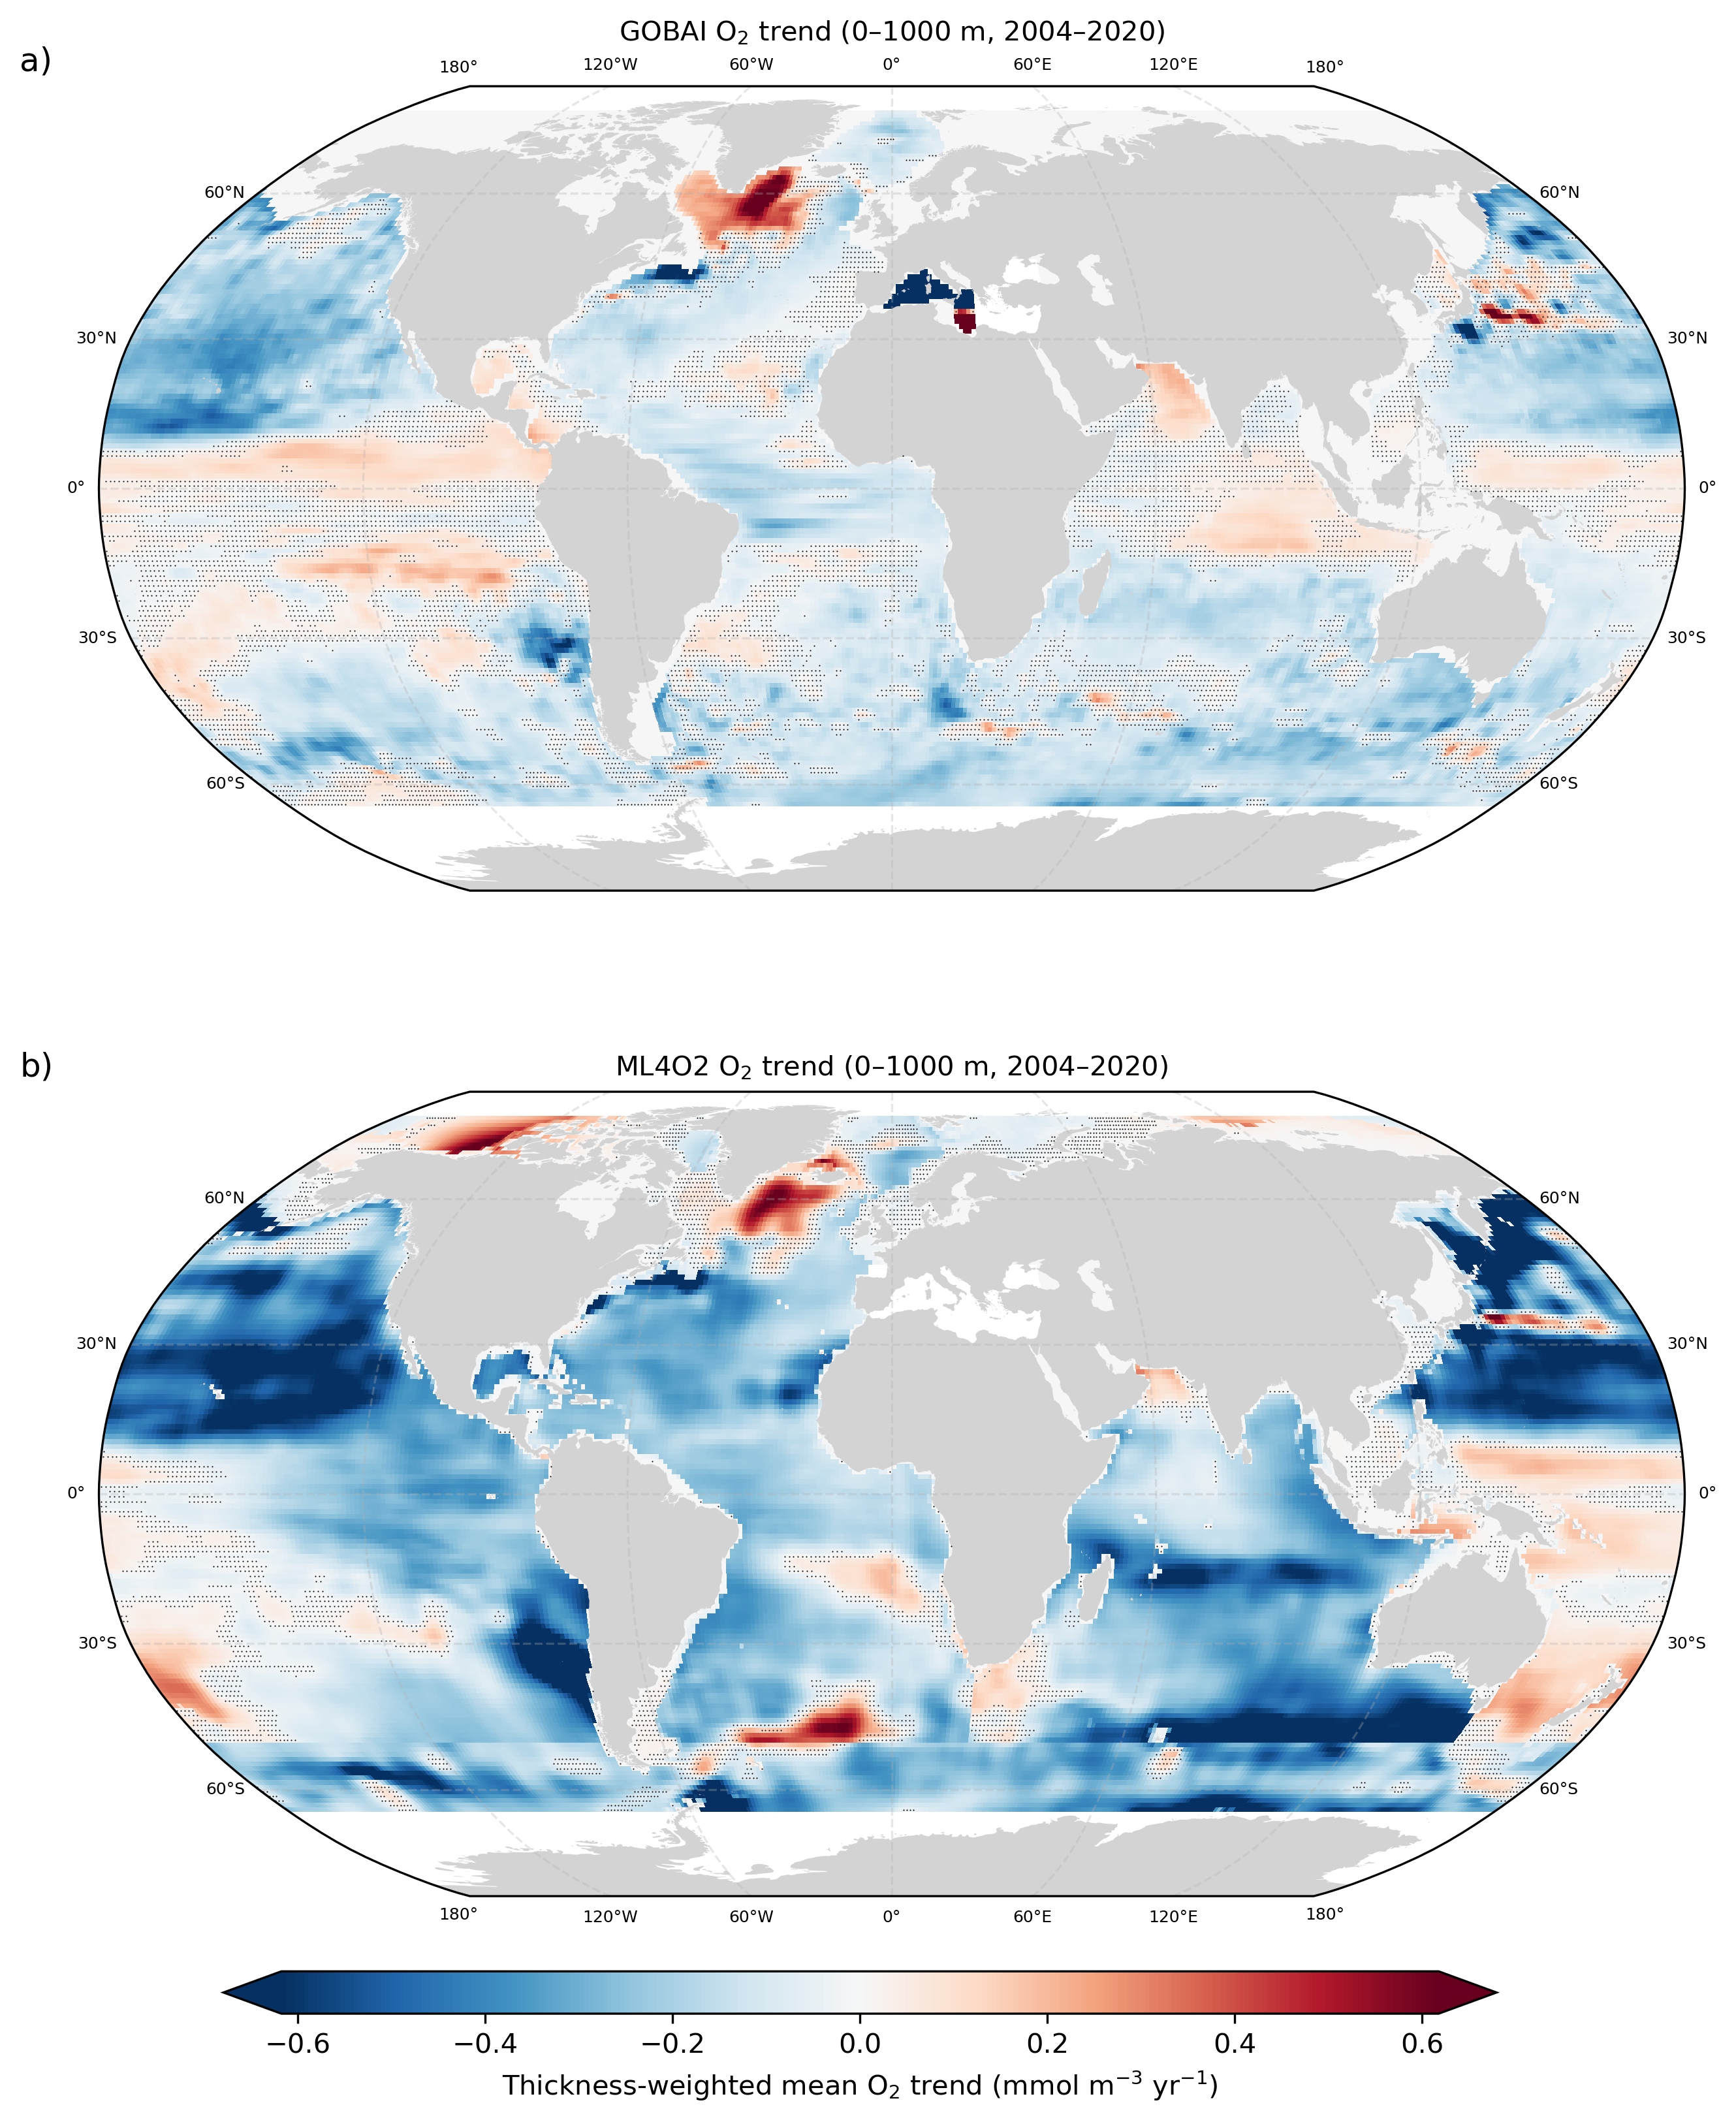

Saved: figs/FigS_A_GOBAI_vs_ML4O2_trends_with_nonsig_stippling.png


In [2]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cartopy.mpl.ticker as cticker

from matplotlib.colors import TwoSlopeNorm
from scipy.stats import t as student_t

# ============================================================
# SETTINGS
# ============================================================
TIME0 = "2004-01-01"
TIME1 = "2020-12-31"
ZMIN  = 0
ZMAX  = 1000

PLOT_WHAT = "mean"   # "mean" recommended
PCTL = 98            # robust symmetric color scaling percentile

PVAL_ALPHA = 0.05
ZERO_TREND_TOL = 1e-12

STIPPLE_SIZE = 1.0
STIPPLE_COLOR = "black"

OUTPATH = "figs/FigS_A_GOBAI_vs_ML4O2_trends_with_nonsig_stippling.png"

# ============================================================
# HELPERS
# ============================================================
def mask_mediterranean(lat, lon):
    return (lat >= 30) & (lat <= 46) & (lon >= -6) & (lon <= 37)

def slope_and_se_1d(y, tvec):
    """
    Regression of y against tvec.
    Returns slope, standard error of slope, p-value.
    """
    y = np.asarray(y, dtype=float)
    tvec = np.asarray(tvec, dtype=float)

    m = np.isfinite(y) & np.isfinite(tvec)
    n = int(m.sum())
    if n < 3:
        return np.nan, np.nan, np.nan

    yy = y[m]
    tt = tvec[m]

    tbar = tt.mean()
    ybar = yy.mean()

    tt_c = tt - tbar
    yy_c = yy - ybar

    sxx = np.sum(tt_c**2)
    if sxx <= 0 or not np.isfinite(sxx):
        return np.nan, np.nan, np.nan

    slope = np.sum(tt_c * yy_c) / sxx
    intercept = ybar - slope * tbar

    yhat = intercept + slope * tt
    resid = yy - yhat

    df = n - 2
    if df <= 0:
        return slope, np.nan, np.nan

    s2 = np.sum(resid**2) / df
    se_slope = np.sqrt(s2 / sxx)

    if not np.isfinite(se_slope) or se_slope == 0:
        return slope, se_slope, np.nan

    tstat = slope / se_slope
    pval = 2.0 * student_t.sf(np.abs(tstat), df)

    return slope, se_slope, pval

# ============================================================
# LOAD DATA
# ============================================================
ds  = xr.load_dataset("data/CONTENT_DIC_v2-3.nc")          # GOBAI-like
ito = xr.load_dataset("data/o2_NN_ship+Argo_ensmean.nc")   # ML4O2

# ============================================================
# GOBAI: trend field over 0-1000 dbar
# ============================================================
g = ds.sel(time=slice(TIME0, TIME1)).sel(pres=slice(ZMIN, ZMAX))

t_year_g = ((g["time"] - g["time"].isel(time=0)) / np.timedelta64(1, "D")) / 365.25
g = g.assign_coords(t_year=("time", t_year_g.data))

fit_g = g["oxy"].polyfit(dim="t_year", deg=1, skipna=True)
o2_trend_g = fit_g["polyfit_coefficients"].sel(degree=1)  # per year at each depth

dp = g["pres"].diff("pres").reindex(pres=g["pres"], method=None).fillna(0)
dp = dp.broadcast_like(o2_trend_g)

o2_meantrend_gobai = ((o2_trend_g * dp).sum("pres", skipna=True) / dp.sum("pres")).rename("O2_meantrend_gobai")

# thickness-weighted mean O2 time series for significance
o2bar_g_t = (g["oxy"] * dp).sum("pres", skipna=True) / dp.sum("pres")
tg = g["t_year"].values.astype(float)

_, se_g, pval_g = xr.apply_ufunc(
    slope_and_se_1d,
    o2bar_g_t,
    xr.DataArray(tg, dims=("time",), coords={"time": o2bar_g_t["time"]}),
    input_core_dims=[["time"], ["time"]],
    output_core_dims=[[], [], []],
    vectorize=True,
    dask="parallelized",
    output_dtypes=[float, float, float],
)

# ============================================================
# ML4O2: trend field over 0-1000 m
# ============================================================
i = ito.sel(time=slice(TIME0, TIME1)).sel(depth=slice(ZMIN, ZMAX))

t_year_i = ((i["time"] - i["time"].isel(time=0)) / np.timedelta64(1, "D")) / 365.25
i = i.assign_coords(t_year=("time", t_year_i.data))

fit_i = i["o2"].polyfit(dim="t_year", deg=1, skipna=True)
o2_trend_i = fit_i["polyfit_coefficients"].sel(degree=1)

dz = i["depth"].diff("depth").reindex(depth=i["depth"], method=None).fillna(0)
dz = dz.broadcast_like(o2_trend_i)

o2_meantrend_ito = ((o2_trend_i * dz).sum("depth", skipna=True) / dz.sum("depth")).rename("O2_meantrend_ito")

# thickness-weighted mean O2 time series for significance
o2bar_i_t = (i["o2"] * dz).sum("depth", skipna=True) / dz.sum("depth")
ti = i["t_year"].values.astype(float)

_, se_i, pval_i = xr.apply_ufunc(
    slope_and_se_1d,
    o2bar_i_t,
    xr.DataArray(ti, dims=("time",), coords={"time": o2bar_i_t["time"]}),
    input_core_dims=[["time"], ["time"]],
    output_core_dims=[[], [], []],
    vectorize=True,
    dask="parallelized",
    output_dtypes=[float, float, float],
)

# ============================================================
# PREPARE PLOTTING FIELDS
# ============================================================
gobai_2d = o2_meantrend_gobai.transpose("lat", "lon")
ito_2d   = o2_meantrend_ito.transpose("lat", "lon")

lat_g = gobai_2d["lat"].values
ito_2d = ito_2d.sel(lat=slice(lat_g.min(), lat_g.max()))

pval_g = pval_g.transpose("lat", "lon")
pval_i = pval_i.transpose("lat", "lon").sel(lat=slice(lat_g.min(), lat_g.max()))

# Mediterranean mask
lat2d_g, lon2d_g = xr.broadcast(gobai_2d["lat"], gobai_2d["lon"])
lat2d_i, lon2d_i = xr.broadcast(ito_2d["lat"], ito_2d["lon"])

med_g = mask_mediterranean(lat2d_g, lon2d_g)
med_i = mask_mediterranean(lat2d_i, lon2d_i)

gobai_2d = gobai_2d.where(~med_g)
ito_2d   = ito_2d.where(~med_i)

pval_g = pval_g.where(~med_g).where(np.isfinite(gobai_2d))
pval_i = pval_i.where(~med_i).where(np.isfinite(ito_2d))

# non-significant stippling masks, excluding zero-trend cells
nonsig_g = (pval_g >= PVAL_ALPHA) & (np.abs(gobai_2d) > ZERO_TREND_TOL)
nonsig_i = (pval_i >= PVAL_ALPHA) & (np.abs(ito_2d) > ZERO_TREND_TOL)

# Convert to numpy
gobai_map = gobai_2d.values
ito_map   = ito_2d.values

# shared robust symmetric color scale
allvals = np.concatenate([gobai_map.ravel(), ito_map.ravel()])
allvals = allvals[np.isfinite(allvals)]
v = np.nanpercentile(np.abs(allvals), PCTL)
norm = TwoSlopeNorm(vcenter=0.0, vmin=-v, vmax=v)

print(f"Using symmetric color range ±{v:.3f}")

# ============================================================
# PLOT
# ============================================================
fig = plt.figure(figsize=(13, 12), dpi=300)

land = cfeature.NaturalEarthFeature(
    "physical", "land", "50m",
    edgecolor="none", facecolor="lightgrey"
)

# ----------------------------
# Panel a: GOBAI
# ----------------------------
ax1 = fig.add_subplot(2, 1, 1, projection=ccrs.Robinson())
ax1.set_global()
ax1.add_feature(land)
ax1.text(-0.05, 1.05, "a)", transform=ax1.transAxes, fontsize=12, va="top")

gl1 = ax1.gridlines(draw_labels=True, alpha=0.3, linestyle="--")
gl1.top_labels = True
gl1.bottom_labels = False
gl1.left_labels = True
gl1.right_labels = True
gl1.xformatter = cticker.LongitudeFormatter()
gl1.yformatter = cticker.LatitudeFormatter()

fig.canvas.draw()
for lbl in gl1.xlabel_artists + gl1.ylabel_artists:
    lbl.set_fontsize(6)

im1 = ax1.pcolormesh(
    lon2d_g.values, lat2d_g.values, gobai_map,
    transform=ccrs.PlateCarree(),
    cmap="RdBu_r", norm=norm, shading="auto"
)

ax1.scatter(
    lon2d_g.values[nonsig_g.values],
    lat2d_g.values[nonsig_g.values],
    s=STIPPLE_SIZE,
    c=STIPPLE_COLOR,
    marker=".",
    linewidths=0,
    alpha=1.0,
    transform=ccrs.PlateCarree(),
    zorder=4,
)

ax1.set_title(
    f"GOBAI O$_2$ trend (0–1000 m, {TIME0[:4]}–{TIME1[:4]})",
    fontsize=10
)

# ----------------------------
# Panel b: ML4O2
# ----------------------------
ax2 = fig.add_subplot(2, 1, 2, projection=ccrs.Robinson())
ax2.set_global()
ax2.add_feature(land)
ax2.text(-0.05, 1.05, "b)", transform=ax2.transAxes, fontsize=12, va="top")

gl2 = ax2.gridlines(draw_labels=True, alpha=0.3, linestyle="--")
gl2.top_labels = False
gl2.bottom_labels = True
gl2.left_labels = True
gl2.right_labels = True
gl2.xformatter = cticker.LongitudeFormatter()
gl2.yformatter = cticker.LatitudeFormatter()

fig.canvas.draw()
for lbl in gl2.xlabel_artists + gl2.ylabel_artists:
    lbl.set_fontsize(6)

im2 = ax2.pcolormesh(
    lon2d_i.values, lat2d_i.values, ito_map,
    transform=ccrs.PlateCarree(),
    cmap="RdBu_r", norm=norm, shading="auto"
)

ax2.scatter(
    lon2d_i.values[nonsig_i.values],
    lat2d_i.values[nonsig_i.values],
    s=STIPPLE_SIZE,
    c=STIPPLE_COLOR,
    marker=".",
    linewidths=0,
    alpha=1.0,
    transform=ccrs.PlateCarree(),
    zorder=4,
)

ax2.set_title(
    f"ML4O2 O$_2$ trend (0–1000 m, {TIME0[:4]}–{TIME1[:4]})",
    fontsize=10
)

# Shared colorbar
cax = fig.add_axes([0.25, 0.06, 0.5, 0.018])
cbar = fig.colorbar(im1, cax=cax, orientation="horizontal", extend="both")
cbar.set_label(r"Thickness-weighted mean O$_2$ trend (mmol m$^{-3}$ yr$^{-1}$)")

plt.subplots_adjust(hspace=0.25)
fig.savefig(OUTPATH, bbox_inches="tight", dpi=300)
plt.show()

print("Saved:", OUTPATH)

Valid pixels: 49028
Sign disagreement pixels: 7405
Fraction disagreement: 15.10%
Red pixels (disagree + GOBAI significant): 3875 (52.33%)
Black pixels (disagree + GOBAI not significant): 3530 (47.67%)


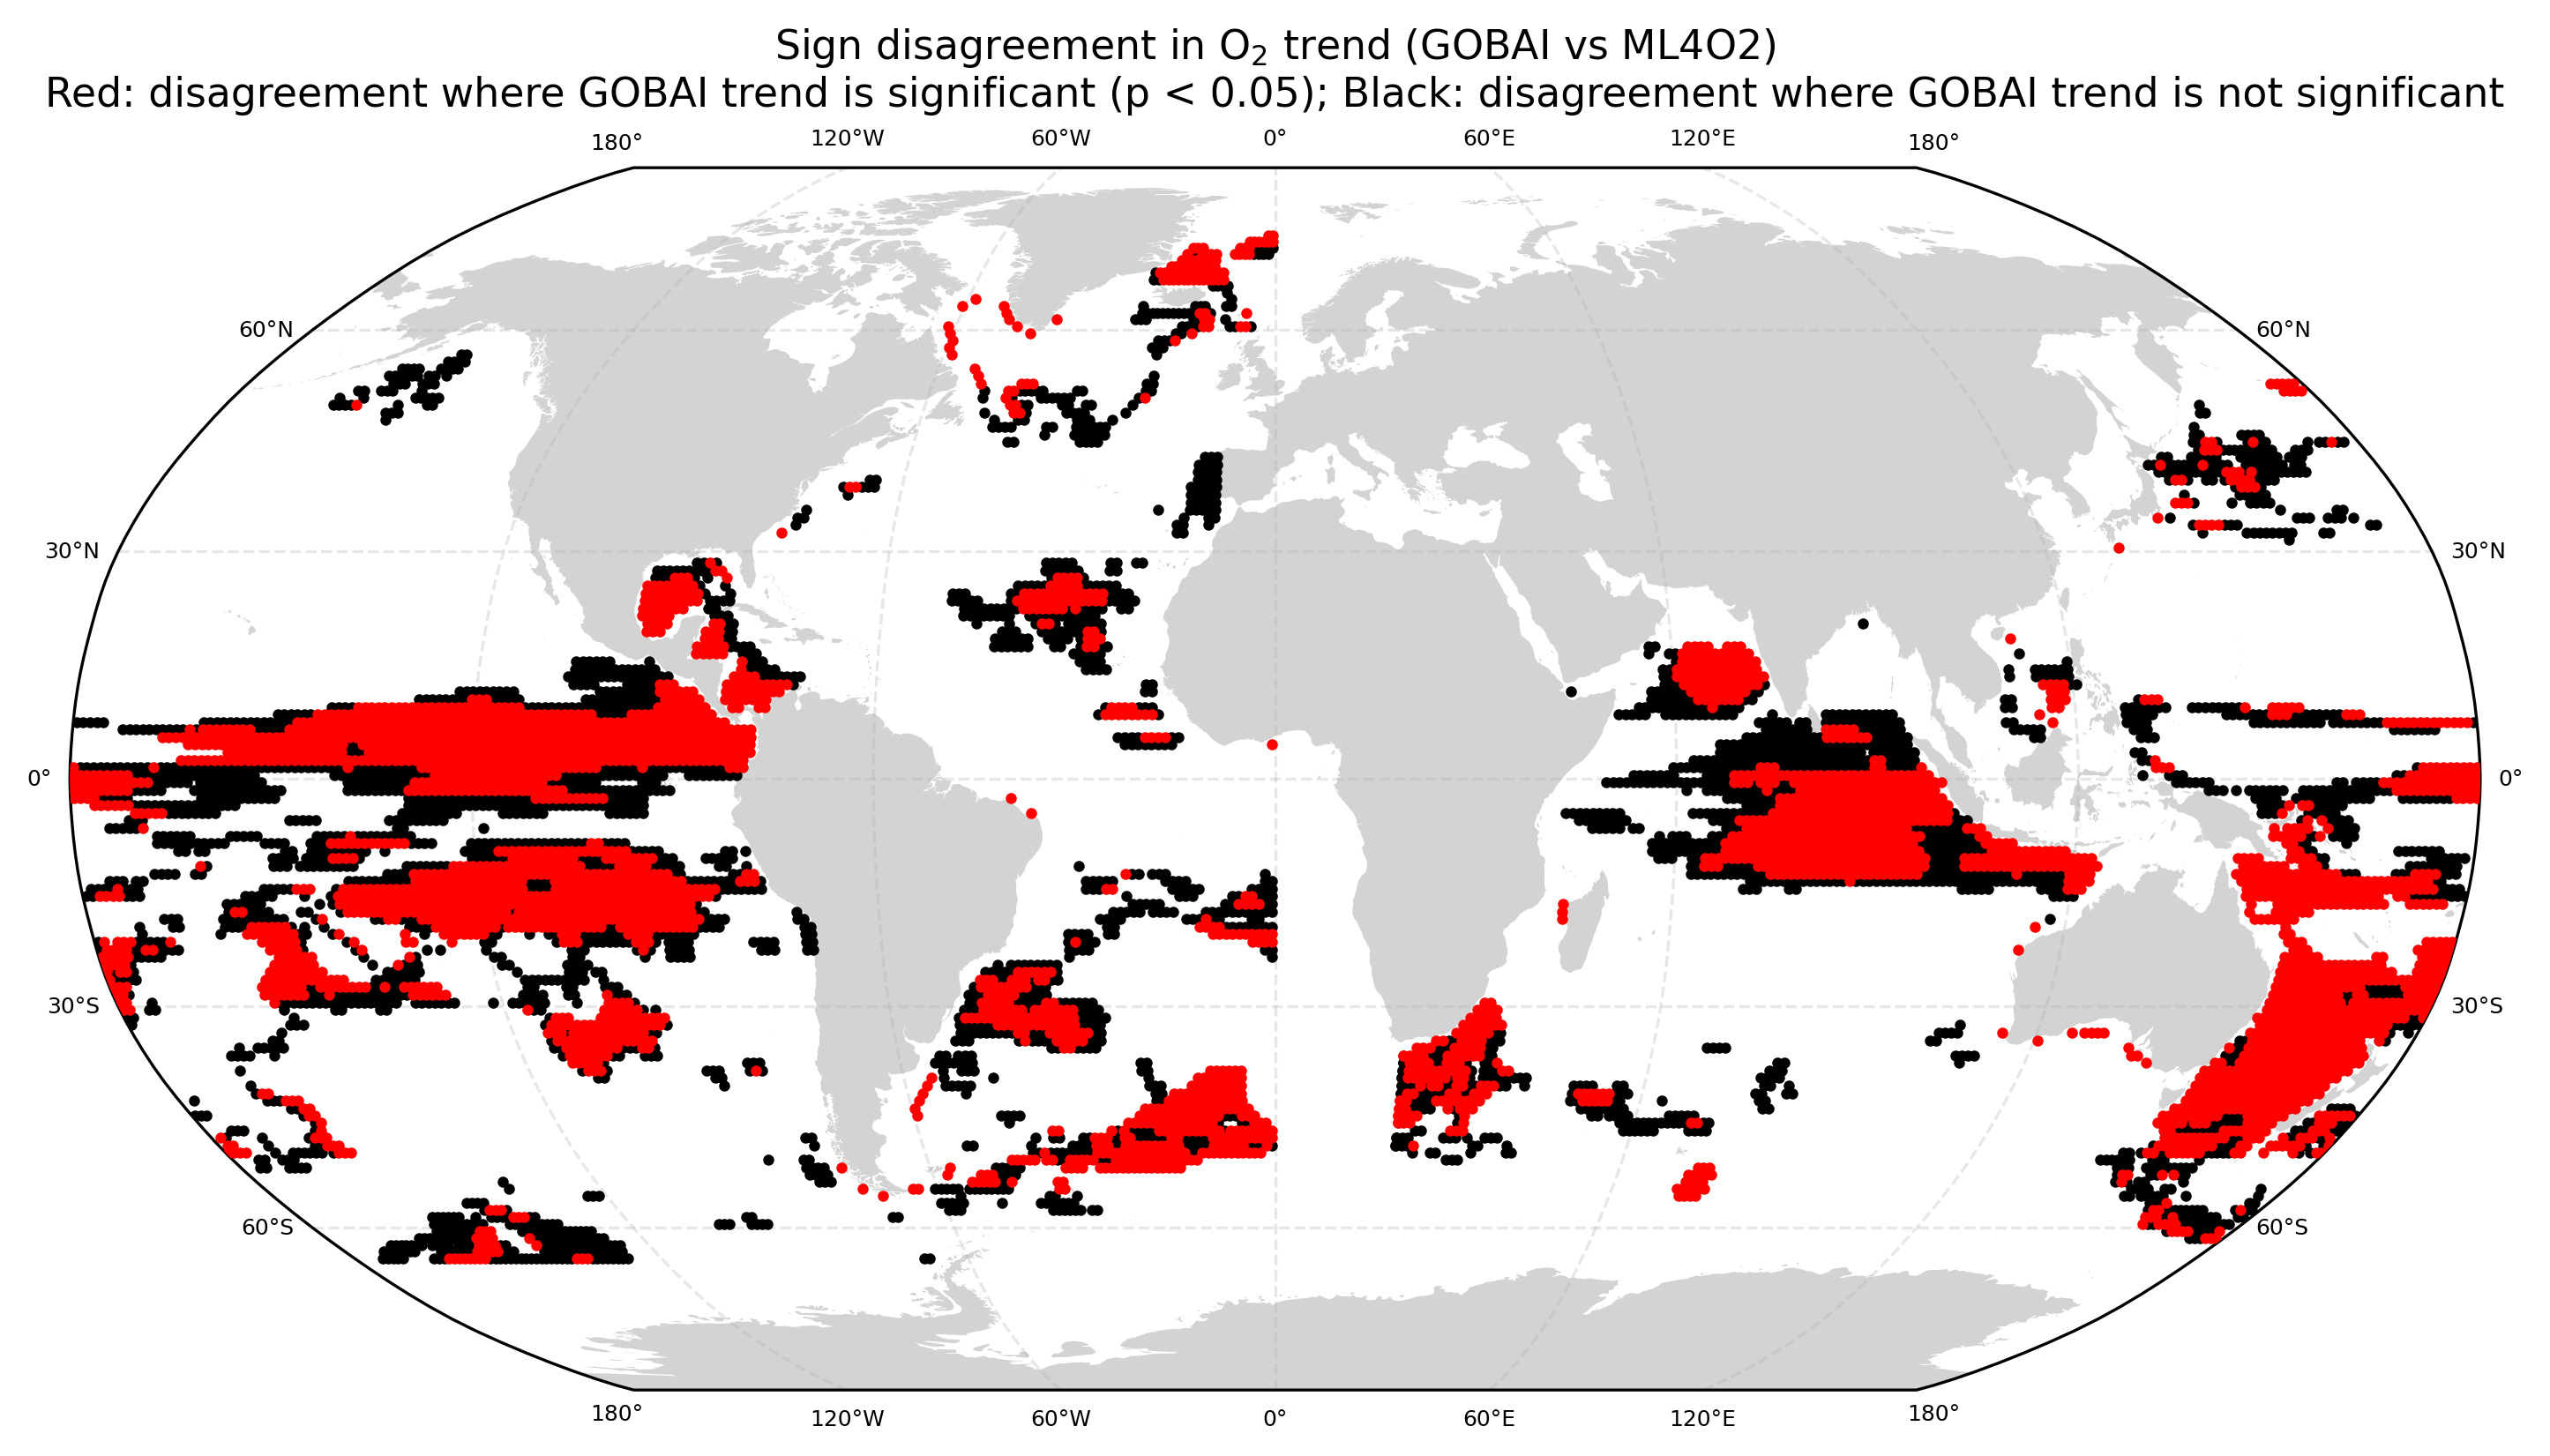

Saved: figs/FigS_B_O2_sign_disagreement_GOBAI_significance.png


In [3]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cartopy.mpl.ticker as cticker
from cartopy.util import add_cyclic_point

# ============================================================
# SETTINGS
# ============================================================
DOTSIZE = 4
OUTPATH = "figs/FigS_B_O2_sign_disagreement_GOBAI_significance.png"

# ============================================================
# REQUIRED INPUTS ALREADY IN MEMORY
# ------------------------------------------------------------
# o2_meantrend_gobai : GOBAI thickness-weighted mean O2 trend
# o2_meantrend_ito   : ML4O2 thickness-weighted mean O2 trend
# pval_g             : GOBAI p-value field for local O2 trend
# mask_mediterranean : function(lat, lon) -> boolean mask
# ============================================================

# ============================================================
# PUT ML4O2 ON SAME LONGITUDE CONVENTION AS GOBAI
# GOBAI: 0–360
# ML4O2: shift from -180–180 to 0–360
# ============================================================
o2_meantrend_ito_shifted = o2_meantrend_ito.assign_coords(
    lon=((o2_meantrend_ito["lon"] + 360) % 360)
).sortby("lon")

# ============================================================
# INTERPOLATE ML4O2 ONTO GOBAI GRID
# ============================================================
ito_on_gobai = o2_meantrend_ito_shifted.interp(
    lat=o2_meantrend_gobai["lat"],
    lon=o2_meantrend_gobai["lon"],
    method="linear"
)

# ============================================================
# MATCH DIMENSIONS
# ============================================================
gtrend = o2_meantrend_gobai.transpose("lat", "lon")
itrend = ito_on_gobai.transpose("lat", "lon")
pval_g = pval_g.transpose("lat", "lon")

# ============================================================
# APPLY MEDITERRANEAN MASK
# ============================================================
lat2d, lon2d = xr.broadcast(gtrend["lat"], gtrend["lon"])
med = mask_mediterranean(lat2d, lon2d)

gtrend = gtrend.where(~med)
itrend = itrend.where(~med)
pval_g = pval_g.where(~med)

# ============================================================
# VALID PIXELS
# ============================================================
valid = np.isfinite(gtrend) & np.isfinite(itrend)

# Opposite sign only
sign_disagree = ((np.sign(gtrend) * np.sign(itrend)) < 0) & valid

# GOBAI significance
gobai_sig = (pval_g < 0.05) & valid

# ------------------------------------------------------------
# Final plotting masks
# black = disagreement where GOBAI is NOT significant
# red   = disagreement where GOBAI IS significant
# ------------------------------------------------------------
mask_red = sign_disagree & gobai_sig
mask_black = sign_disagree & (~gobai_sig)

# ============================================================
# DIAGNOSTICS
# ============================================================
n_valid = int(valid.sum())
n_disagree = int(sign_disagree.sum())
n_red = int(mask_red.sum())
n_black = int(mask_black.sum())

print(f"Valid pixels: {n_valid}")
print(f"Sign disagreement pixels: {n_disagree}")

if n_valid > 0:
    print(f"Fraction disagreement: {100 * n_disagree / n_valid:.2f}%")

if n_disagree > 0:
    print(f"Red pixels (disagree + GOBAI significant): {n_red} ({100 * n_red / n_disagree:.2f}%)")
    print(f"Black pixels (disagree + GOBAI not significant): {n_black} ({100 * n_black / n_disagree:.2f}%)")

# ============================================================
# ADD CYCLIC POINT FOR CLEAN GLOBAL PLOTTING
# ============================================================
lon_vals = gtrend["lon"].values
lat_vals = gtrend["lat"].values

mask_red_cyc, lon_cyc = add_cyclic_point(mask_red.values.astype(float), coord=lon_vals, axis=1)
mask_black_cyc, _ = add_cyclic_point(mask_black.values.astype(float), coord=lon_vals, axis=1)

lon2d_cyc, lat2d_cyc = np.meshgrid(lon_cyc, lat_vals)

mask_red_cyc = mask_red_cyc.astype(bool)
mask_black_cyc = mask_black_cyc.astype(bool)

# ============================================================
# PLOT
# ============================================================
fig = plt.figure(figsize=(12, 6), dpi=300)
ax = fig.add_subplot(1, 1, 1, projection=ccrs.Robinson())
ax.set_global()

land = cfeature.NaturalEarthFeature(
    "physical", "land", "50m",
    edgecolor="none", facecolor="lightgrey"
)
ax.add_feature(land)

gl = ax.gridlines(draw_labels=True, alpha=0.3, linestyle="--")
gl.top_labels = True
gl.bottom_labels = True
gl.left_labels = True
gl.right_labels = True
gl.xformatter = cticker.LongitudeFormatter()
gl.yformatter = cticker.LatitudeFormatter()

fig.canvas.draw()
for lbl in gl.xlabel_artists + gl.ylabel_artists:
    lbl.set_fontsize(6)

# Black = sign disagreement, GOBAI not significant
ax.scatter(
    lon2d_cyc[mask_black_cyc],
    lat2d_cyc[mask_black_cyc],
    s=DOTSIZE,
    color="black",
    transform=ccrs.PlateCarree(),
    zorder=4,
)

# Red = sign disagreement, GOBAI significant
ax.scatter(
    lon2d_cyc[mask_red_cyc],
    lat2d_cyc[mask_red_cyc],
    s=DOTSIZE,
    color="red",
    transform=ccrs.PlateCarree(),
    zorder=5,
)

ax.set_title(
    "Sign disagreement in O$_2$ trend (GOBAI vs ML4O2)\n"
    "Red: disagreement where GOBAI trend is significant (p < 0.05); "
    "Black: disagreement where GOBAI trend is not significant",
    fontsize=11
)

fig.savefig(OUTPATH, bbox_inches="tight", dpi=300)
plt.show()

print("Saved:", OUTPATH)